# Лабораторна 2. Від сирих даних до нейромережі

У цій лабораторній роботі ви пройдете повний цикл роботи з табличним датасетом для задачі регресії — від завантаження до порівняння моделей:

- дослідницький аналіз даних (EDA): загальний огляд, гістограми, кореляції;
- обробка пропусків і викидів;
- інженерія ознак;
- baseline: множинна лінійна регресія;
- нейромережа — підбір архітектури, функцій активації, оптимізатора власними експериментами;
- чесне порівняння моделей на test за метриками регресії (MSE, RMSE, MAE, R²).

Демо-ноутбук з лекції 3-4 — основа, звертайтесь до нього як до довідника, коли щось незрозуміло.

## 0. Опрацюйте демо-ноутбук з лекції
Прогляньте пояснення ноутбуку і запустіть всі клітинки демо-ноутбуку (крім тих секцій, в яких вказано, що їх запускати не можна).
Після цього дайте тут відповідь на запитання:
1. Чому для заповнення пропусків було обрано метод kNN?
2. Чому при тренуванні лінійної регресії train і val порівнюються лише на основі MSE, а після тренування на основі багатьох функцій? Проекспериментуйте в межах тренування з вибором функції і поділіться результатами.
3. Які висновки після клітинки 2.6 в демо Ви можете зробити?
4. Поясни для чого потрібен baseline в лінійній регресії і як він вираховується? Що є baseline для нейронної мережі?
5. Продемонструй дію всіх функцій активації на графіку функцій, згенерувавши 1000 випадкових значень Х і порахувавши для них Y через ці функції.
6. Яким чином в нейронній мережі утворилася така кількість параметрів, яка вказана після виконання 3.3?
7. Чи оптимально вибрано кількість епох в 3.5?

### 0.1 Мої відповіді:

1. Чому для заповнення пропусків було обрано метод kNN?

Цей підхід дозволяє зберегти всі рядки, не втрачаючи гіпотетично цінну інформацію (імпутація). Пропущене значення не усереднюється загалом по колонці, а індивідуально передбачається на основі решти ознак конкретного рядка.

2. Чому при тренуванні лінійної регресії train і val порівнюються лише на основі MSE, а після тренування на основі багатьох функцій? Проекспериментуйте в межах тренування з вибором функції і поділіться результатами.

Під час тренування нам потрібна функція втрат, яка є диференційованою. MSE утворює гладку опуклу параболу, по якій алгоритм градієнтного спуску дуже легко "спускається" до мінімуму. Вона сильно штрафує за великі помилки (помилка підноситься до квадрата), що змушує модель швидше коригувати серйозні промахи.

Після завершення тренування модель оцінюють за багатьма метриками, щоб отримати більш повну картину:
  * RMSE - показує похибку в одиницях самого таргету, що легше інтерпретувати.
  * MAE - менш чутлива до викидів у даних.
  * R^2 - демонструє частку дисперсії цільової змінної, яку пояснює побудована модель.

Експериментальне тренування лінійної регресії з різними функціями втрат при lr = 0.1 показало:
1. MSE забезпечує найшвидшу збіжність (близько 10 епох) завдяки квадратичній природі градієнта, який робить великі кроки при значних похибках.
2. MAE демонструє повільну та рівномірну збіжність (потрібно ~30 епох), оскільки її градієнт постійний за модулем і не прискорює навчання на початкових етапах.
3. Huber Loss забезпечує найбільш гладке та стійке зниження помилки, комбінуючи властивості MSE та MAE.

В результаті MSE була оптимальною функцією втрат для тренування моделі за швидкістю збіжності.

  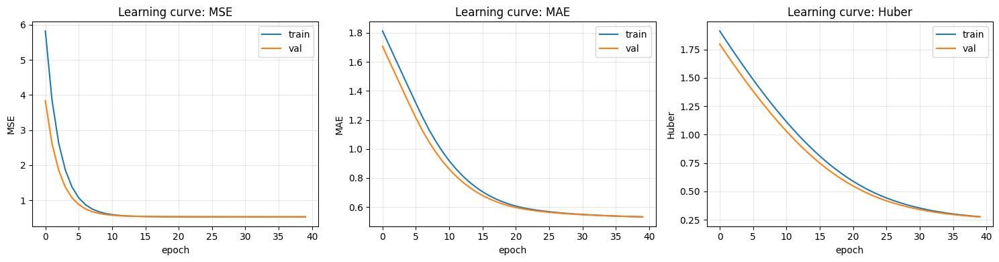

3. Які висновки після клітинки 2.6 в демо Ви можете зробити?

Всі ознаки пройшли стандартизацію і мають однаковий масштаб, абсолютне значення кожної ваги напряму відображає силу впливу відповідної ознаки на кінцевий прогноз.

Виведення ваг дозволяє на практиці перевірити, чи виправдала себе інженерія ознак і чи стали нові змінні дійсно вагомими для моделі.

4. Поясни для чого потрібен baseline в лінійній регресії і як він вираховується? Що є baseline для нейронної мережі?

Для лінійної регресії бейзлайном слугує прогноз середнього значення цільової змінної з навчальної вибірки. Якщо модель не перевершує цей поріг, вона вважається непридатною. У свою чергу, для нейронної мережі бейзлайном виступає сама лінійна регресія. Це дозволяє обґрунтувати доцільність ускладнення архітектури й перевірити, чи дійсно нелінійні активації покращують точність прогнозу порівняно з простішою моделлю.

5. Продемонструй дію всіх функцій активації на графіку функцій, згенерувавши 1000 випадкових значень Х і порахувавши для них Y через ці функції.

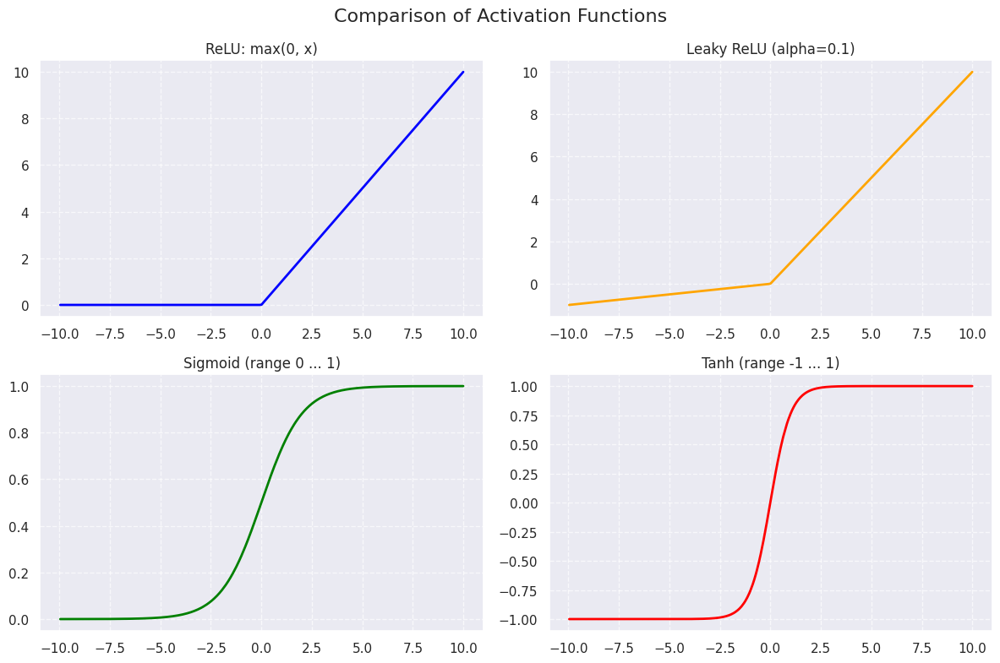

In [2255]:
import torch
import matplotlib.pyplot as plt

x = torch.empty(1000).uniform_(-10, 10)

x, _ = torch.sort(x)

y_relu = torch.relu(x)
y_leaky_relu = torch.nn.functional.leaky_relu(x, negative_slope=0.1)
y_sigmoid = torch.sigmoid(x)
y_tanh = torch.tanh(x)

x_np = x.numpy()

fig, axs = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Comparison of Activation Functions', fontsize=16)

axs[0, 0].plot(x_np, y_relu.numpy(), color='blue', linewidth=2)
axs[0, 0].set_title('ReLU: max(0, x)')
axs[0, 0].grid(True, linestyle='--', alpha=0.7)

axs[0, 1].plot(x_np, y_leaky_relu.numpy(), color='orange', linewidth=2)
axs[0, 1].set_title('Leaky ReLU (alpha=0.1)')
axs[0, 1].grid(True, linestyle='--', alpha=0.7)

axs[1, 0].plot(x_np, y_sigmoid.numpy(), color='green', linewidth=2)
axs[1, 0].set_title('Sigmoid (range 0 ... 1)')
axs[1, 0].grid(True, linestyle='--', alpha=0.7)

axs[1, 1].plot(x_np, y_tanh.numpy(), color='red', linewidth=2)
axs[1, 1].set_title('Tanh (range -1 ... 1)')
axs[1, 1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

6. Яким чином в нейронній мережі утворилася така кількість параметрів, яка вказана після виконання 3.3?

Кількість параметрів складається з ваг та зсувів кожного із лінійних шарів.

Операція в кожному шарі `Linear(in_features, out_features)` обчислюється як:

$$(\text{in_features} \times \text{out_features}) + \text{out_features}$$

де $(\text{in_features} \times \text{out_features})$ - кількість ваг, а $\text{out_features}$ - кількість зсувів (по одному на кожен вихідний нейрон).

По кожному шару:

1. `Linear(in_features=7, out_features=64)`
* Ваги: $7 \times 64 = 448$
* Зсуви: $64$
* Усього: $448 + 64 = \mathbf{512}$

2. `Linear(in_features=64, out_features=32)`
* Ваги: $64 \times 32 = 2048$
* Зсуви: $32$
* Усього: $2048 + 32 = \mathbf{2080}$


3. `Linear(in_features=32, out_features=1)`
* Ваги: $32 \times 1 = 32$
* Зсуви: $1$
* Усього: $32 + 1 = \mathbf{33}$

Загальна сума: $512 + 2080 + 33 = 2625$

7. Чи оптимально вибрано кількість епох в 3.5?

Вибір 200 епох є доволі оптимальним.

Глобальний мінімум помилки валідації фіксується в діапазоні 150–180 епох із val_loss = 0.3336. Починаючи з 200-ї епохи, train_loss продовжує стабільно падати, досягаючи 0.2604 на 999-й епосі, тоді як val_loss деградує, зростає та сильніше коливається, доходячи до 0.3418 на 910-й епосі.

---
## 1. Датасети

Ви отримаєте один з 10 датасетів нижче. Усі — задачі регресії на Hugging Face: табличні дані, здебільшого числові ознаки, від кількасот до кількадесяти тисяч рядків.

1. **[King County House Sales](https://huggingface.co/datasets/kraina/house_sales_in_king_county)** — 21 613 продажів будинків (Вашингтон, 2014–2015). Таргет: `price`. ⚠️ `load_dataset("kraina/house_sales_in_king_county")` не працює (застарілий loading-скрипт) — вантажте напряму: `load_dataset("parquet", data_files="https://huggingface.co/datasets/kraina/house_sales_in_king_county/resolve/main/data/house_sales_king_county.parquet")`.
2. **[Diamonds](https://huggingface.co/datasets/jdxcosta/diamonds)** — 53 940 діамантів. Таргет: `price`. Ознаки: вага (`carat`), огранка, колір, чистота, розміри.
3. **[Concrete Compressive Strength](https://huggingface.co/datasets/foundry-ml/dataset_concrete_compressive_strength)** — 1 030 замісів бетону. Таргет: міцність на стиск. Усі ознаки числові (склад суміші + вік).
4. **[Auto MPG](https://huggingface.co/datasets/scikit-learn/auto-mpg)** — 398 автомобілів. Таргет: `mpg` (витрата пального). Найменший і найпростіший датасет зі списку.
5. **[Wine Quality](https://huggingface.co/datasets/codesignal/wine-quality)** — 1 599 (червоне) + 4 898 (біле) вин. Таргет: `quality` (оцінка 3–9). Усі ознаки — хімічний склад, числові.
6. **[Laptop Price](https://huggingface.co/datasets/Ammok/laptop_price_prediction)** — 977 + 325 ноутбуків. Таргет: `Price`. Частина ознак текстові (`RAM`, `Storage`, `CPU`) — доведеться парсити в числа.
7. **[Bike Sharing Demand](https://huggingface.co/datasets/t22000t/bike-sharing-tabular)** — 17 379 годинних записів прокату велосипедів. Таргет: `cnt`. Часові й погодні ознаки.
8. **[Ames House Prices](https://huggingface.co/datasets/t22000t/house-prices-tabular)** — 1 460 будинків, 79 ознак. Таргет: `SalePrice`. Найбільше категоріальних ознак зі списку — гарна практика на encoding.
9. **[Medical Insurance Cost](https://huggingface.co/datasets/harishsohani/medical-insurance-cost-prediction)** — 1 338 застрахованих. Таргет: `charges`. Компактний, мало ознак — хороший старт, якщо часу мало. ⚠️ У репозиторії кілька CSV одразу (`Xtrain`/`Xtest`/`insurance.csv`) — вкажіть файл явно: `load_dataset("harishsohani/medical-insurance-cost-prediction", data_files="insurance.csv")`.
10. **[Abalone](https://huggingface.co/datasets/mstz/abalone)** — 4 177 молюсків. Таргет: `number_of_rings` (вік). Усі ознаки — фізичні виміри, окрім `sex`.

Решта (2–5, 7–8, 10) вантажаться напряму — `load_dataset("<repo_id>")` без додаткових аргументів, HF-токен не потрібен.

### 1.1. Який датасет мій?

Визначте самі власний датасет: беремо Ваше ПІБ, рахуємо SHA-256 хеш, залишок від ділення на 10 — це індекс у списку датасетів вище (0 → перший, 9 → останній).

**Формат ПІБ:** точно як у списку групи — `Прізвище Ім'я По-батькові`, по одному пробілу між словами, без зайвих пробілів на початку/в кінці. Якщо використаєте інший формат - **не зарахую лабу**!!!

In [2256]:
import hashlib

DATASETS = [
    "King County House Sales",
    "Diamonds",
    "Concrete Compressive Strength",
    "Auto MPG",
    "Wine Quality",
    "Laptop Price",
    "Bike Sharing Demand",
    "Ames House Prices",
    "Medical Insurance Cost",
    "Abalone",
]

FULL_NAME = "Поліванчук Нікіта Русланович"  # TODO: впишіть своє ПІБ точно як у списку групи

dataset_index = int(hashlib.sha256(FULL_NAME.encode("utf-8")).hexdigest(), 16) % len(DATASETS)
print(f"Ваш датасет (#{dataset_index + 1}):", DATASETS[dataset_index])

Ваш датасет (#8): Ames House Prices


---
## 2. Що потрібно зробити

Нижче — загальний план роботи, без коду: код і пояснення до кожного кроку дивіться в **демо-ноутбуці лекції 3-4**, номери розділів позначені в дужках. Ваша задача — повторити той самий підхід на своєму датасеті, а не скопіювати код один в один: у вашого датасету інші колонки, інші типи пропусків (чи їх взагалі нема), інші викиди (чи їх нема) — рішення на кожному кроці обґрунтовуйте під свої дані, а не тому, що "так було в демо".

### 2.1. Підготовка даних

1. Завантажте свій датасет (демо 1.1) і перетворіть на `pandas.DataFrame` (1.2).
2. Зробіть спліт **train / val / test** одразу, до будь-якого аналізу (1.3) — і поясніть своїми словами, чому саме в такому порядку (нагадування: data leakage).
3. Загальний огляд (`head`/`info`/`describe`, 1.4).
4. Обробка пропусків (1.5) — **якщо вони є**. Немає пропусків — так і напишіть, це теж валідний результат, не треба їх штучно вигадувати.
5. EDA (1.6): хоча б гістограми і кореляційна матриця. Що впадає в очі у ваших даних — capping, скошені розподіли, мультиколінеарність?
6. Обробка викидів (1.7) — **за потреби**, з обґрунтуванням: звідки взявся викид і чому саме таке рішення (видалити / трансформувати / залишити).
7. Інженерія ознак (1.8) — **за потреби**: чи є сенс комбінувати/прибирати ознаки з високою кореляцією між собою.

### 2.2. Baseline: множинна лінійна регресія

Стандартизація ознак (2.1), тензори (2.2), тренування `nn.Linear` (2.3), крива навчання (2.4), метрики на test — MSE/RMSE/MAE/R² (2.5), інтерпретація ваг (2.6).

Це ваш **варіант #1**, точка відліку для всього, що далі.

### 2.3. Нейромережа: щонайменше 2 різні архітектури

За зразком розділу 3 демо: `nn.Sequential` з прихованими шарами, ReLU, оптимізатор Adam.

Спробуйте **мінімум 2 архітектури**, які відрізняються не косметично — напр. різна кількість шарів, різна ширина шарів, чи інша функція активації (3.2). Кожна — окремий варіант.

### 2.4. Підбір гіперпараметрів: щонайменше 3 зміни

Візьміть архітектуру, яка показала себе краще, і поекспериментуйте з гіперпараметрами: learning rate, оптимізатор (SGD/Adam), кількість епох, розмір batch (якщо вирішите його ввести) тощо. Змінюйте **по одному параметру за раз** — інакше не зрозумієте, що саме вплинуло на результат.

**Разом (2.2 + 2.3 + 2.4):** щонайменше 5 варіантів моделі (1 лінійна + 2 архітектури + 2 гіперпараметри), до **10 варіантів** — якщо є час і бажання поекспериментувати більше, це тільки заохочується.

### 2.5. Логування і порівняння

Кожен варіант (2.2-2.4) логуйте в TensorBoard в окрему підпапку `RUNS_DIR` (як у 2.3/3.5 демо) — з осмисленою назвою (`linear`, `nn_v1_2layers`, `nn_v2_deeper`, `nn_v2_lr_0.001`, ...), щоб потім усі криві можна було накласти одна на одну (3.8 демо) і візуально порівняти.

Наприкінці зведіть усі варіанти в одну таблицю (модель → MSE/RMSE/MAE/R² на test) і дайте коротку письмову відповідь:
- Яка модель перемогла і наскільки суттєво?
- Чи виправдала себе нейромережа порівняно з лінійною регресією на вашому датасеті?
- Що з ваших змін (архітектура чи гіперпараметри) дало найбільший ефект?

---
## 3. Gradio-застосунок: порівняння всіх варіантів наживо

Побудуйте аппку для своїх моделей

---
### Як здавати лабу

У форму (https://forms.gle/8Dbc9zB8L5tsNuNEA) здати посилання на **публічний** репозиторій, який містить:

1. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Файли всіх натренованих варіантів моделі** (2.2-2.4) — лінійна регресія + всі варіанти нейромережі, кожен окремим `.pt` файлом.
3. **Логи TensorBoard** — папка `runs/` з усіма прогонами, щоб можна було відкрити криві навчання, не перезапускаючи ноутбук.
4. **Таблицю результатів** — `results.csv` з порівнянням усіх варіантів (модель, MSE, RMSE, MAE, R² на test).
5. **Відео демонстрації TensorBoard & Gradio-застосунку** замість скріншотів цього разу: 60-90 секунд. На відео показуєте тренування і роботу моделей і коротко розповідаєте про цікаве (можливості, обмеження, труднощі тренування).
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab2/nn_task.ipynb
/lab2/models/linear.pt
/lab2/models/nn_v1.pt
/lab2/models/nn_v2.pt
/lab2/models/...        (усі інші варіанти з 2.3-2.4)
/lab2/runs/*
/lab2/results.csv
/lab2/demo.mp4
```

## Хід Роботи

### Глобальні налаштування

In [2257]:
import sys
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import torch

DRAW_PLOTS=True

In [2258]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
print("Seed locked:", SEED)

Seed locked: 42


In [2259]:
from google.colab import drive
drive.mount("/content/drive")

ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab2"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)

MODELS_DIR = os.path.join(ARTIFACT_DIR, "models")
os.makedirs(MODELS_DIR, exist_ok=True)

print("Artifacts are stored in:", ARTIFACT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Artifacts are stored in: /content/drive/MyDrive/ai_systems/lab2


In [2260]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### Підготовка даних

#### Завантаження датасету

In [2261]:
!pip install -q datasets
from datasets import load_dataset

In [2262]:
ds = load_dataset("t22000t/house-prices-tabular", split="train")
ds

Dataset({
    features: ['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorc

In [2263]:
df = ds.to_pandas()
df.shape

(1460, 81)

#### Первинний огляд даних

In [2264]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,None,Reg,Lvl,AllPub,...,0,None,None,None,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,None,Reg,Lvl,AllPub,...,0,None,None,None,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,None,IR1,Lvl,AllPub,...,0,None,None,None,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,None,IR1,Lvl,AllPub,...,0,None,None,None,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,None,IR1,Lvl,AllPub,...,0,None,None,None,0,12,2008,WD,Normal,250000


In [2265]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

#### Обробка пропущених значень

##### Корекція типів даних

У специфікації датасету значення NA позначає відсутність характеристики об'єкта. Під час завантаження даних pandas інтерпретував такі позначення як пропущені значення (NaN). Тому для відповідних стовпців відновлюємо початкове значення NA.

In [2266]:
nan_cols = [
  "Alley", "BsmtQual", "BsmtCond", "BsmtExposure",
  "BsmtFinType1", "BsmtFinType2", "FireplaceQu",
  "GarageType", "GarageFinish", "GarageQual",
  "GarageCond", "PoolQC", "Fence", "MiscFeature",
]

df[nan_cols] = df[nan_cols].fillna("NA")

Аналогічно відновлюємо значення "None", що позначає відсутність облицювання фасаду, оскільки pandas інтерпретував їх як None.

In [2267]:
df["MasVnrType"] = df["MasVnrType"].fillna("None")

MSSubClass є категоріальною ознакою, а не числовою величиною. Її значення представляють коди класів будинків, тому перетворюємо стовпець на рядковий тип.

In [2268]:
df["MSSubClass"] = df["MSSubClass"].astype(str)

Перевіримо онолвені значення

In [2269]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NA,Reg,Lvl,AllPub,...,0,NA,NA,NA,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NA,Reg,Lvl,AllPub,...,0,NA,NA,NA,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NA,IR1,Lvl,AllPub,...,0,NA,NA,NA,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NA,IR1,Lvl,AllPub,...,0,NA,NA,NA,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NA,IR1,Lvl,AllPub,...,0,NA,NA,NA,0,12,2008,WD,Normal,250000


In [2270]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   object 
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          1460 non-null   object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

##### Аналіз пропущених значень

Після виправлення інтерпретації NA у датасеті все ще залишаються пропущені значення. Це свідчить про те, що частина пропусків не пов'язана з початковим перетворенням даних і потребує окремого аналізу.

Нульові значення також потребують уваги: залежно від ознаки вони можуть позначати відсутність певної характеристики або бути повноцінним числовим значенням.

Тому спочатку проаналізуємо кількість і частку пропусків та нулів у числових ознаках.

In [2271]:
def check_numeric_values(df):
  numeric_cols = df.select_dtypes(include="number").columns

  result = pd.DataFrame({
    'Nulls': df[numeric_cols].isna().sum(),
    'Null %': df[numeric_cols].isna().mean() * 100,
    'Zeros': (df[numeric_cols] == 0).sum(),
    'Zero %': (df[numeric_cols] == 0).mean() * 100
  })

  return result[(result['Nulls'] > 0) | (result['Zeros'] > 0)]

check_numeric_values(df)

,Nulls,Null %,Zeros,Zero %
LotFrontage,259,17.739726,0,0.000000
MasVnrArea,8,0.547945,861,58.972603
BsmtFinSF1,0,0.000000,467,31.986301
BsmtFinSF2,0,0.000000,1293,88.561644
BsmtUnfSF,0,0.000000,118,8.082192
TotalBsmtSF,0,0.000000,37,2.534247
2ndFlrSF,0,0.000000,829,56.780822
LowQualFinSF,0,0.000000,1434,98.219178
BsmtFullBath,0,0.000000,856,58.630137
BsmtHalfBath,0,0.000000,1378,94.383562


###### Ознака LotFrontage

| Feature | Nulls | Null % | Zeros | Zero % |
| --- | --- | --- | --- | --- |
| LotFrontage |	259 |	17.739726 |	0 |	0.000000 |

Ознака LotFrontage містить 259 пропущених значень (17,74 %), але не містить нульових значень.

Оскільки ця ознака характеризує довжину межі ділянки вздовж вулиці, нуль не є автоматично коректною заміною пропуску. Тому залишаємо ці значення пропущеними до вибору відповідної стратегії імпутації.

Заповнення виконаємо пізніше, використовуючи параметри, обчислені лише на навчальній вибірці.

###### Ознака GarageYrBlt

| Feature | Nulls | Null % | Zeros | Zero % |
| --- | --- | --- | --- | --- |
| GarageYrBlt | 81 | 5.547945 | 0 | 0.000000 |
| GarageCars | 0 | 0.000000 | 81 | 5.547945 |
| GarageArea | 0 | 0.000000 | 81 | 5.547945 |

Ознака GarageYrBlt містить 81 пропущене значення. Водночас GarageCars і GarageArea мають по 81 нульовому значенню.

Цей збіг може свідчити про те, що пропущений рік побудови гаража пов'язаний із його відсутністю. Перевіримо ці спостереження за допомогою інших ознак.

In [2272]:
df.loc[df["GarageYrBlt"].isna(),
  ["GarageYrBlt", "GarageCars", "GarageArea", "SalePrice"]]

,GarageYrBlt,GarageCars,GarageArea,SalePrice
39,NaN,0,0,82000
48,NaN,0,0,113000
78,NaN,0,0,136500
88,NaN,0,0,85000
89,NaN,0,0,123600
...,...,...,...,...
1349,NaN,0,0,122000
1407,NaN,0,0,112000
1449,NaN,0,0,92000
1450,NaN,0,0,136000


Перевірка показує, що в усіх рядках із пропущеним GarageYrBlt значення GarageCars і GarageArea дорівнюють нулю. Це підтверджує, що в цих спостереженнях гараж відсутній.

Оскільки рік побудови гаража для таких об'єктів невизначений, заповнюємо пропуски значенням YearBuilt.

In [2273]:
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(df["YearBuilt"])

###### Ознака MasVnrArea

| Feature | Nulls | Null % | Zeros | Zero % |
| --- | --- | --- | --- | --- |
| MasVnrArea |	8 |	0.547945 |	861 |	58.972603 |

Ознака MasVnrArea містить 8 пропущених значень і 861 нульове значення. Щоб з'ясувати причину пропусків, перевіримо відповідні значення MasVnrType.

In [2274]:
df.loc[df["MasVnrArea"].isna(),
  ["MasVnrArea", "MasVnrType", "OverallQual", "SalePrice"]]

,MasVnrArea,MasVnrType,OverallQual,SalePrice
234,NaN,None,6,216500
529,NaN,None,6,200624
650,NaN,None,7,205950
936,NaN,None,7,184900
973,NaN,None,7,182000
977,NaN,None,7,199900
1243,NaN,None,10,465000
1278,NaN,None,8,237000


У всіх вісьмох спостереженнях із пропущеним MasVnrArea ознака MasVnrType має значення None. Це вказує на відсутність кам'яного облицювання, а не на невідому площу наявного облицювання.

Тому в цих випадках пропущену площу можна інтерпретувати як нуль і замінити значення NaN на 0.

In [2275]:
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)

###### Ознака Electrical

Ознака Electrical містить лише один пропущений запис. Аналогічно до LotFrontage, для запобігання витоку даних заповнення цього пропуску буде виконано після розбиття датасету на навчальну та тестову вибірки.

#### Кодування порядкових ознак

Згідно зі специфікацією датасету, низка категоріальних ознак є порядковими, оскільки їхні значення мають чітко виражений порядок чи градацію. Перетворимо ці ознаки на числові відповідно до їхньої рангової шкали.

In [2276]:
ordinal_maps = {
    "BsmtCond":     {"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "BsmtExposure": {"NA": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFinType1": {"NA": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "BsmtFinType2": {"NA": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "BsmtQual":     {"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},

    "ExterCond":    {"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "ExterQual":    {"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},

    "Fence":        {"NA": 0, "MnWw": 1, "GdWo": 2, "MnPrv": 3, "GdPrv": 4},

    "FireplaceQu":  {"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},

    "Functional":   {"Sal": 1, "Sev": 2, "Maj2": 3, "Maj1": 4, "Mod": 5, "Min2": 6, "Min1": 7, "Typ": 8},

    "GarageCond":   {"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "GarageFinish": {"NA": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "GarageQual":   {"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},

    "HeatingQC":    {"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},

    "KitchenQual":  {"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},

    "LandSlope":    {"Sev": 1, "Mod": 2, "Gtl": 3},
    "LotShape":     {"IR3": 1, "IR2": 2, "IR1": 3, "Reg": 4},

    "Electrical":   {"Mix": 1, "FuseP": 2, "FuseF": 3, "FuseA": 4, "SBrkr": 5},
    "Utilities":    {"ELO": 0, "NoSeWa": 1, "NoSewr": 2, "AllPub": 3},

    "PoolQC":       {"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "PavedDrive":   {"N": 0, "P": 1, "Y": 2},

    "CentralAir":   {"N": 0, "Y": 1},
}

for col, mapping in ordinal_maps.items():
  df[col] = df[col].map(mapping)

#### Видалення ідентифікатора

Ознака Id є унікальним ключем для кожного запису. Вона не містить корисної інформації про характеристики нерухомості та може створити хибні зв'язки під час навчання моделі, тому видалимо її.

In [2277]:
df = df.drop(columns=["Id"])

#### Розбиття даних

Розділимо датасет на три вибірки:
- навчальну (60 %)
- валідаційну (20 %)
- тестову (20 %).


Фіксуємо random_state, щоб забезпечити відтворюваність результатів.

In [2278]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(df, test_size=0.4, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=SEED)

print(f"Train: {train_df.shape}")
print(f"Validation: {val_df.shape}")
print(f"Test: {test_df.shape}")

Train: (876, 80)
Validation: (292, 80)
Test: (292, 80)


#### Заповнення пропусків

##### Ознака LotFrontage



Для ознаки LotFrontage використаємо медіану в межах кожного району (Neighborhood). Такий підхід враховує можливі відмінності між районами.

Якщо для певного району немає доступних значень, використаємо загальну медіану навчальної вибірки.

In [2279]:
global_median = train_df["LotFrontage"].median()
train_median = train_df.groupby("Neighborhood")["LotFrontage"].median()

for df in [train_df, val_df, test_df]:
  df["LotFrontage"] = df["LotFrontage"].fillna(df["Neighborhood"].map(train_median).fillna(global_median))

##### Ознака Electrical

У всьому датасеті було лише одне пропущене значення в ознаці Electrical, заповнимо його модою.

In [2280]:
electrical_mode = train_df["Electrical"].mode()[0]

for split_df in (train_df, val_df, test_df):
  split_df["Electrical"] = split_df["Electrical"].fillna(electrical_mode)

#### Перевірка пропущених значень

Після заповнення пропусків повторно перевіримо числові ознаки навчальної вибірки, щоб переконатися, що в них не залишилося пропущених значень.

In [2281]:
for name, split_df in [
  ("Train", train_df),
  ("Validation", val_df),
  ("Test", test_df),
]:
  print(f"{name}:", split_df.isna().sum().sum())

Train: 0
Validation: 0
Test: 0


#### Розвідувальний аналіз даних (EDA)

##### Класифікація типів ознак

Для подальшої обробки згрупуємо ознаки за трьома типами:
- числові (numeric)
- порядкові (ordinal)
- номінальні (nominal),

і також окремо дати.

In [2282]:
TARGET = "SalePrice"

ordinal_cols = list(ordinal_maps.keys()) + [
  "OverallQual",
  "OverallCond",
]

nominal_cols = [
  "MSSubClass", "MSZoning", "Street", "Alley", "LandContour",
  "LotConfig", "Neighborhood", "Condition1", "Condition2", "BldgType",
  "HouseStyle", "RoofStyle", "RoofMatl", "Exterior1st", "Exterior2nd",
  "MasVnrType", "Foundation", "Heating", "GarageType", "MiscFeature",
  "SaleType", "SaleCondition"
]

dates = [
  "YearBuilt", "YearRemodAdd", "GarageYrBlt", "MoSold", "YrSold"
]

numeric_cols = [col for col in df.columns if col not in ordinal_cols + nominal_cols + dates]

##### Аналіз розподілів числових ознак

Розглянемо розподіли числових ознак за допомогою гістограм. Щоб оцінити їхню форму, асиметрію, наявність екстремальних значень і можливі відхилення.

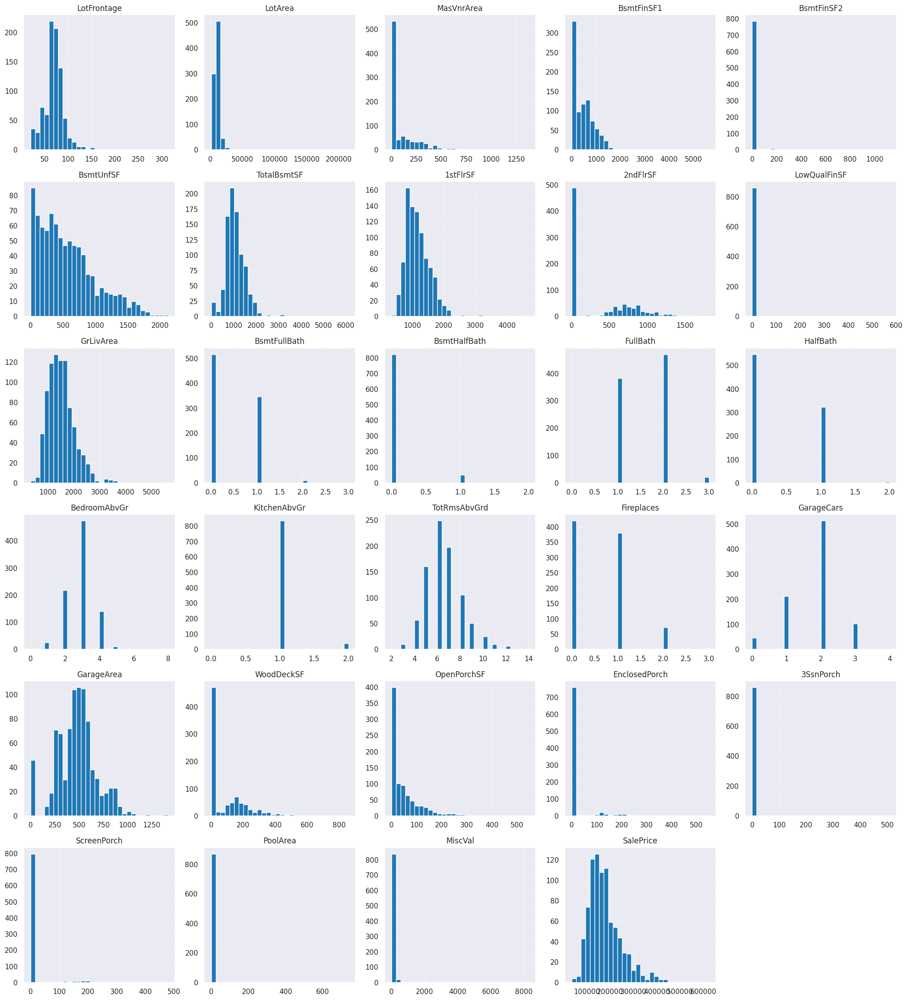

In [2283]:
if DRAW_PLOTS:
  train_df[numeric_cols].hist(figsize=(20, 22), bins=30)
  plt.tight_layout()
  plt.show()

За гістограмами можна виявити ознаки з асиметричними розподілами, проте для виявлення потенційних викидів важливо також врахувати їхній зв'язок із ціною продажу будинку.

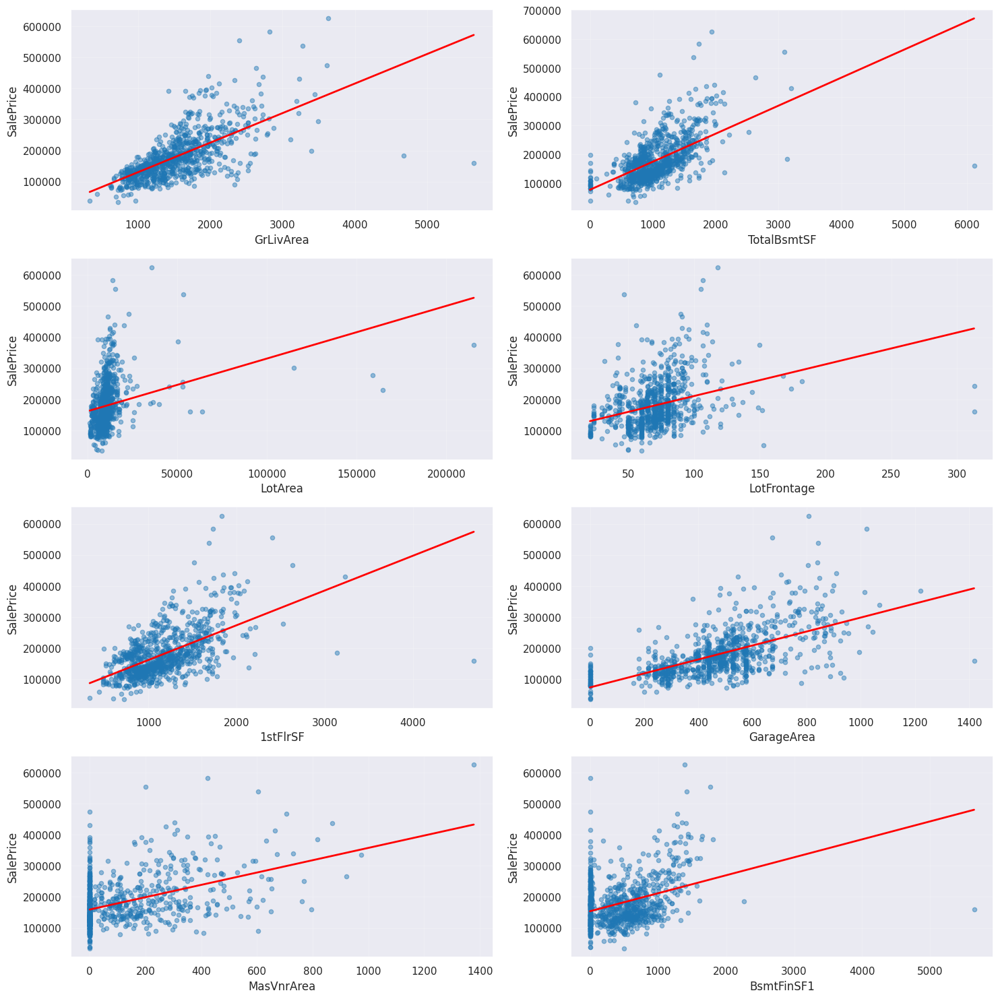

In [2284]:
features = [
    "GrLivArea",
    "TotalBsmtSF",
    "LotArea",
    "LotFrontage",
    "1stFlrSF",
    "GarageArea",
    "MasVnrArea",
    "BsmtFinSF1",
]

if DRAW_PLOTS:
  fig, axes = plt.subplots(4, 2, figsize=(15, 15))

  for ax, col in zip(axes.flat, features):
      x = train_df[col]
      y = train_df[TARGET]

      ax.scatter(x, y, alpha=0.45, s=20)

      mask = x.notna() & y.notna()
      x_valid = x[mask]
      y_valid = y[mask]

      if x_valid.nunique() > 1:
          slope, intercept = np.polyfit(x_valid, y_valid, 1)

          x_line = np.linspace(x_valid.min(), x_valid.max(), 200)
          y_line = slope * x_line + intercept

          ax.plot(x_line, y_line, color="red", linewidth=2)

      ax.set_xlabel(col)
      ax.set_ylabel(TARGET)
      ax.grid(alpha=0.2)

  plt.tight_layout()
  plt.show()


На діаграмах розсіювання можна помітити записи, що суттєво відрізняються від основної маси даних за площею або розташуванням.

Розглянемо ці записи детально

In [2285]:
train_df[(train_df["GrLivArea"] > 4000)][["GrLivArea", "SalePrice", "SaleCondition", "Neighborhood"]]

,GrLivArea,SalePrice,SaleCondition,Neighborhood
523,4676,184750,Partial,Edwards
1298,5642,160000,Partial,Edwards


In [2286]:
train_df[(train_df["TotalBsmtSF"] > 5000)][["TotalBsmtSF", "SalePrice", "SaleCondition", "Neighborhood"]]


,TotalBsmtSF,SalePrice,SaleCondition,Neighborhood
1298,6110,160000,Partial,Edwards


In [2287]:
train_df[train_df["LotFrontage"] > 250][["LotFrontage", "SalePrice", "SaleCondition", "Neighborhood"]]

,LotFrontage,SalePrice,SaleCondition,Neighborhood
1298,313.0,160000,Partial,Edwards
934,313.0,242000,Normal,NAmes


In [2288]:
train_df[train_df["1stFlrSF"] > 4000][["1stFlrSF", "SalePrice", "SaleCondition", "Neighborhood"]]

,1stFlrSF,SalePrice,SaleCondition,Neighborhood
1298,4692,160000,Partial,Edwards


In [2289]:
train_df[train_df["BsmtFinSF1"] > 5000][["BsmtFinSF1", "SalePrice", "SaleCondition", "Neighborhood"]]

,BsmtFinSF1,SalePrice,SaleCondition,Neighborhood
1298,5644,160000,Partial,Edwards


За результатами перевірки можна побачити один запис з аномально великими параметрами, проте низькою ціному. Тому його було вирішено вилучити з вибірки.

In [2290]:
train_df = train_df[train_df["GrLivArea"] <= 4000]

##### Аналіз розподілу порядкових та номінальних ознак

Розглянемо розподіл значень порядкових і номінальних ознак за допомогою діаграм частот.

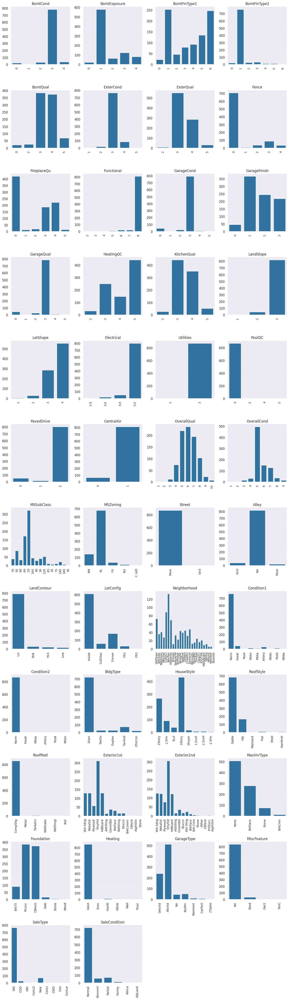

In [2291]:
def subplot_distributions(dataframe, list_of_columns):
    nrows = int(np.ceil(len(list_of_columns)/4))
    ncols = 4
    fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 4*nrows))
    ax = ax.ravel()
    for i, column in enumerate(list_of_columns):
        sns.countplot(data=dataframe, x=column, ax=ax[i])
        ax[i].set_title(column, fontsize=12)
        plt.setp(ax[i].get_xticklabels(), rotation=90, fontsize=10)
        ax[i].set_xlabel("")
        ax[i].set_ylabel("")
    if len(list_of_columns) < nrows*ncols:
        for i in range(nrows*ncols - len(list_of_columns)):
            ax[nrows*ncols - 1 - i].set_axis_off()
    fig.tight_layout()

if DRAW_PLOTS:
  subplot_distributions(train_df, ordinal_cols + nominal_cols)

Візуальний аналіз показує, що для деяких ознак розподіл значень є суттєво незбалансованим: одна категорія переважає над іншими. Щоб кількісно оцінити цей ефект, розглянемо найчастіше значення кожної ознаки та його частку у вибірці.

In [2292]:
stats = {
  'Feature': [],
  'Mode': [],
  'Occurrence %': [],
  'Status': [],
  'Correlation with Target': []
}

threshold = 90.0

for col in ordinal_cols + nominal_cols:
  stats['Feature'].append(col)

  mode = train_df[col].mode()[0]
  stats['Mode'].append(mode)

  proportion = np.round((train_df[col] == mode).sum() / len(train_df) * 100, 1)
  stats['Occurrence %'].append(proportion)

  if train_df[col].nunique() == 2 and train_df[TARGET].nunique() == 2:
    corr = train_df[col].corr(train_df[TARGET])
  elif col in ordinal_cols:
    corr = train_df[col].corr(train_df[TARGET], method='spearman')
  else:
    corr = np.nan

  stats['Status'].append('' if proportion < threshold else 'Severely skewed')

  stats['Correlation with Target'].append(np.round(corr, 3) if pd.notna(corr) else np.nan)

stats_df = pd.DataFrame(stats)
stats_df

,Feature,Mode,Occurrence %,Status,Correlation with Target
0,BsmtCond,3,89.7,,0.274
1,BsmtExposure,1,66.4,,0.356
2,BsmtFinType1,1,28.9,,0.355
3,BsmtFinType2,1,86.8,,0.056
4,BsmtQual,3,43.9,,0.668
5,ExterCond,3,87.6,,-0.022
6,ExterQual,3,62.9,,0.669
7,Fence,0,80.9,,-0.182
8,FireplaceQu,0,48.1,,0.530
9,Functional,8,92.4,Severely skewed,0.142


За результатами аналізу встановлено, що для низки ознак понад 90% спостережень припадає на одну категорію. Такі ознаки мають низьку варіативність і потенційно містять обмежену інформацію для моделювання. Тому такі ознаки було вирішено вилучити.

In [2293]:
low_variance_cols = stats_df.loc[
  stats_df["Occurrence %"] > threshold,
  "Feature"
].tolist()

for split_df in (train_df, val_df, test_df):
  split_df.drop(columns=low_variance_cols, inplace=True)

Після вилучення ознак оновимо списки порядкових і номінальних ознак, щоб вони відповідали актуальному складу даних.

In [2294]:
ordinal_cols = [col for col in ordinal_cols if col not in low_variance_cols]
nominal_cols = [col for col in nominal_cols if col not in low_variance_cols]

##### Аналіз кореляцій між ознаками

Для дослідження взаємозв'язків між числовими та закодованими порядковими ознаками побудуємо теплову карту кореляцій.

In [2295]:
def corr_mat(df, figsize):
    corr = df.corr().round(2)
    f, ax = plt.subplots(figsize=figsize)
    mask = np.zeros_like(corr, dtype=bool)
    mask[np.triu_indices_from(mask)] = True
    sns.heatmap(corr, mask=mask, vmin=-1, vmax=1, center=0,
                cmap="plasma", square=False, lw=2, annot=True, cbar=False)
    plt.show()

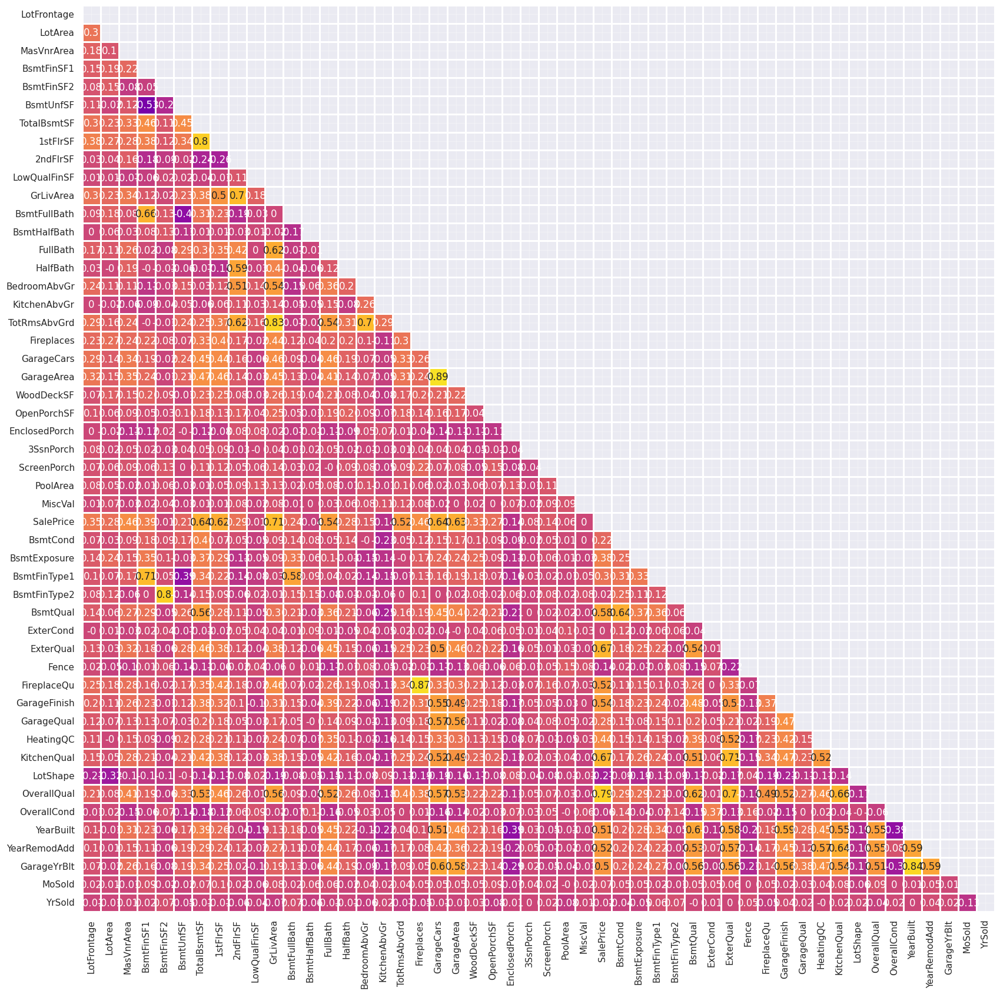

In [2296]:
if DRAW_PLOTS:
  corr_mat(train_df[numeric_cols + ordinal_cols + dates], (20, 20))

На тепловій карті спостерігаються декілька пар ознак із високою кореляцією. Наприклад, GarageCars і GarageArea мають коефіцієнт кореляції приблизно 0.89, Fireplaces і FireplaceQu - 0.87, а YearBuilt і GarageYrBlt - 0.84.

Такі результати свідчать про наявність ознак, які можуть частково описувати одну й ту саму характеристику нерухомості.

Також помітні сильні зв'язки між характеристиками житлового простору: GrLivArea і TotRmsAbvGrd, TotalBsmtSF і 1stFlrSF. Це закономірно, оскільки площа будинку пов'язана з кількістю кімнат, а загальна площа підвалу - з площею першого поверху.

Для подальшого аналізу додатково сформуємо таблицю пар ознак із модулем кореляції не менше 0,6. Щоб систематизувати найсильніші зв'язки та визначити, які з них варто врахувати під час інженерії ознак.

In [2297]:
corr = train_df[numeric_cols + ordinal_cols + dates].corr()

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

high_corr = (
    upper.stack()
    .reset_index()
)

high_corr.columns = ["Feature 1", "Feature 2", "Correlation"]

high_corr["Abs Correlation"] = high_corr["Correlation"].abs()

high_corr = high_corr.sort_values(
    "Abs Correlation",
    ascending=False
)

high_corr[high_corr["Abs Correlation"] >= 0.6]

,Feature 1,Feature 2,Correlation,Abs Correlation
760,GarageCars,GarageArea,0.887813,0.887813
747,Fireplaces,FireplaceQu,0.866170,0.866170
1216,YearBuilt,GarageYrBlt,0.839513,0.839513
451,GrLivArea,TotRmsAbvGrd,0.827866,0.827866
279,TotalBsmtSF,1stFlrSF,0.804999,0.804999
217,BsmtFinSF2,BsmtFinType2,0.801778,0.801778
1008,SalePrice,OverallQual,0.789655,0.789655
171,BsmtFinSF1,BsmtFinType1,0.713525,0.713525
1125,ExterQual,KitchenQual,0.710740,0.710740
462,GrLivArea,SalePrice,0.708247,0.708247


Для оцінювання лінійного зв'язку між ознаками та цільовою змінною SalePrice обчислимо кореляції всіх числових і закодованих порядкових ознак із ціною продажу.

In [2298]:
target_corr = train_df[numeric_cols + ordinal_cols + dates].corr()["SalePrice"].sort_values(ascending=False)
target_corr

,SalePrice
SalePrice,1.000000
OverallQual,0.789655
GrLivArea,0.708247
ExterQual,0.673983
KitchenQual,0.665352
GarageCars,0.637545
TotalBsmtSF,0.637256
GarageArea,0.625287
1stFlrSF,0.616579
BsmtQual,0.580596


Найсильніший додатний зв'язок із ціною продажу мають OverallQual (0.79), GrLivArea (0.71), ExterQual (0.67), KitchenQual (0.67), GarageCars (0.64) і TotalBsmtSF (0.64).

Це свідчить про те, що вища загальна якість будинку, більша житлова площа, краща якість зовнішнього оздоблення та кухні, а також місткіший гараж зазвичай пов'язані з вищою ціною продажу.

Для оцінювання форми розподілів числових ознак розглянемо коефіцієнти асиметрії.

In [2299]:
skew = train_df[numeric_cols + ordinal_cols + dates].skew().sort_values(ascending=False)
skew[skew.abs() > 1]

,0
PoolArea,17.847540
MiscVal,17.302786
LotArea,11.448669
3SsnPorch,9.591622
LowQualFinSF,9.218378
BsmtFinSF2,4.331075
KitchenAbvGr,4.053054
ScreenPorch,4.016955
BsmtHalfBath,3.876926
BsmtFinType2,3.462902


Сильно скошені розподіли можуть ускладнювати моделювання, тому для окремих невід'ємних  ознак надалі будемо розглядати логарифмічне перетворення.

#### Інженерія ознак

На основі результатів первинного аналізу, кореляційної матриці та кількох ітерацій підготовки даних було сформовано набір похідних ознак.

Замість використання великої кількості окремих показників створено агреговані характеристики, співвідношення та бінарні індикатори. Для ознак із вираженою правосторонньою асиметрією застосовано логарифмічне перетворення.

Перетворення застосовуються однаково до навчальної, валідаційної та тестової вибірок.

In [2300]:
def apply_fe(d):
  # Area & Count Aggregates
  d["TotalSF"] = d["TotalBsmtSF"] + d["1stFlrSF"] + d["2ndFlrSF"]
  d["TotalOutdoorSF"] = d["WoodDeckSF"] + d["OpenPorchSF"] + d["EnclosedPorch"] + d["3SsnPorch"] + d["ScreenPorch"]
  d["TotalBath"] = d["FullBath"] + 0.5 * d["HalfBath"] + d["BsmtFullBath"] + 0.5 * d["BsmtHalfBath"]

  # Space Ratios
  d["AvgRoomSize"] = d["GrLivArea"].div(d["TotRmsAbvGrd"].replace(0, np.nan)).fillna(0)
  d["BedroomRatio"] = d["BedroomAbvGr"].div(d["TotRmsAbvGrd"].replace(0, np.nan)).fillna(0)
  d["BathPerBedroom"] = d["TotalBath"].div(d["BedroomAbvGr"].replace(0, np.nan)).fillna(0)
  d["GarageAreaPerCar"] = d["GarageArea"].div(d["GarageCars"].replace(0, np.nan)).fillna(0)

  # Log Transforms
  d["log_LotArea"] = np.log1p(d["LotArea"])
  d["log_LotFrontage"] = np.log1p(d["LotFrontage"])

  # Dates
  d["HouseAge"] = d["YrSold"] - d["YearBuilt"]
  d["RemodAge"] = d["YrSold"] - d["YearRemodAdd"]

  # Flags
  d["HasDeck"] = (d["WoodDeckSF"] > 0).astype(int)
  d["HasOpenPorch"] = (d["OpenPorchSF"] > 0).astype(int)
  d["HasEnclPorch"] = (d["EnclosedPorch"] > 0).astype(int)
  d["HasScreenPorch"] = (d["ScreenPorch"] > 0).astype(int)
  d["HasMasVnr"] = (d["MasVnrArea"] > 0).astype(int)

  drop_cols = [
      "GrLivArea", "1stFlrSF", "2ndFlrSF",
      "TotalBsmtSF", "BsmtUnfSF", "BsmtFinSF1", "BsmtFinSF2", "LowQualFinSF",
      "FullBath", "HalfBath","BsmtFullBath", "BsmtHalfBath",
      "OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch",
      "WoodDeckSF", "MasVnrArea",
      "Fireplaces",
      'TotRmsAbvGrd', 'BedroomAbvGr',
      'LotArea', 'LotFrontage',
      "YrSold", "MoSold", "YearBuilt", "YearRemodAdd", "GarageYrBlt",
      "GarageQual", "GarageArea",
      "MiscVal", "PoolArea",
  ]

  d.drop(columns=drop_cols, inplace=True)

  return d

train_df, val_df, test_df = map(apply_fe, (train_df, val_df, test_df))

Після створення нових характеристик повторно проаналізуємо кореляції, щоб оцінити, наскільки нові ознаки пов'язані між собою та з цільовою змінною, а також перевірити, чи залишилися сильні лінійні залежності.

На цьому етапі для аналізу зв'язку з ціною додатково використаємо логарифм цільової змінної.

In [2301]:
log_saleprice = np.log1p(train_df["SalePrice"])

corr_df = train_df[train_df.select_dtypes(include="number").columns].copy()

corr_df["SalePrice"] = log_saleprice

corr = corr_df.corr()

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

high_corr = upper.stack().reset_index()

high_corr.columns = ["Feature 1", "Feature 2", "Correlation"]

high_corr["Abs Correlation"] = high_corr["Correlation"].abs()

high_corr = high_corr.sort_values(
    "Abs Correlation",
    ascending=False
)

high_corr[high_corr["Abs Correlation"] >= 0.6]

,Feature 1,Feature 2,Correlation,Abs Correlation
425,SalePrice,TotalSF,0.813352,0.813352
48,OverallQual,SalePrice,0.811569,0.811569
104,ExterQual,KitchenQual,0.710740,0.710740
34,OverallQual,ExterQual,0.697800,0.697800
525,log_LotArea,log_LotFrontage,0.685314,0.685314
391,GarageCars,SalePrice,0.676058,0.676058
334,KitchenQual,SalePrice,0.669900,0.669900
109,ExterQual,SalePrice,0.663653,0.663653
49,OverallQual,TotalSF,0.663419,0.663419
43,OverallQual,KitchenQual,0.662750,0.662750


Кореляція ознак із логарифмованою ціною

In [2302]:
corr_df = train_df[train_df.select_dtypes(include="number").columns].copy()

corr_df["SalePrice"] = np.log1p(train_df["SalePrice"])

target_corr = corr_df.corr()["SalePrice"].sort_values(ascending=False)

target_corr

,SalePrice
SalePrice,1.000000
TotalSF,0.813352
OverallQual,0.811569
GarageCars,0.676058
KitchenQual,0.669900
ExterQual,0.663653
TotalBath,0.653556
BsmtQual,0.610604
GarageFinish,0.593062
AvgRoomSize,0.555121


#### Кодування номінальних ознак

Перед переходом до навчання моделей необхідно перетворити номінальні ознаки у числовий формат, придатний для використання алгоритмами машинного навчання.

Під час кодування використаємо параметр handle_unknown="infrequent_if_exist", який передбачає обробку категорій, що не зустрічалися під час навчання кодера. Параметр min_frequency=10 дозволяє об'єднати рідкісні категорії в окрему групу, якщо для неї створюється відповідний стовпець.

In [2303]:
from sklearn.preprocessing import OneHotEncoder

nominal_cols_present = [c for c in nominal_cols if c in train_df.columns]

ohe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False)
ohe.fit(train_df[nominal_cols_present])

def apply_ohe(d):
    enc = pd.DataFrame(ohe.transform(d[nominal_cols_present]),
                       columns=ohe.get_feature_names_out(nominal_cols_present), index=d.index)
    return pd.concat([d.drop(columns=nominal_cols_present), enc], axis=1)

train_encoded, val_encoded, test_encoded = map(apply_ohe, (train_df, val_df, test_df))

In [2304]:
train_encoded.shape

(874, 147)

In [2305]:
train_encoded.info()

<class 'pandas.core.frame.DataFrame'>
Index: 874 entries, 314 to 1126
Columns: 147 entries, LotShape to SaleCondition_infrequent_sklearn
dtypes: float64(120), int64(27)
memory usage: 1010.6 KB


Після кодування навчальна вибірка містить 874 записи та 147 стовпців. Усі ознаки представлені числовими типами float64 та int64, тому таблиця готова до використання

### Перетворення даних у тензори

In [2306]:
TARGET = "SalePrice"

X_train, y_train = train_encoded.drop(columns=TARGET), train_encoded[TARGET]
X_val,   y_val   = val_encoded.drop(columns=TARGET),   val_encoded[TARGET]
X_test,  y_test  = test_encoded.drop(columns=TARGET),  test_encoded[TARGET]

In [2307]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)
Xtr, Xva, Xte = (scaler.transform(X) for X in (X_train, X_val, X_test))

ylog_tr = np.log1p(y_train.values)
y_mu, y_sd = ylog_tr.mean(), ylog_tr.std()
def y_fwd(y): return (np.log1p(y) - y_mu) / y_sd
def y_inv(z): return np.expm1(z * y_sd + y_mu)

In [2308]:
def T(a): return torch.tensor(np.asarray(a), dtype=torch.float32)
Xtr_t, Xva_t, Xte_t = T(Xtr), T(Xva), T(Xte)
ytr_t, yva_t = T(y_fwd(y_train.values)).unsqueeze(1), T(y_fwd(y_val.values)).unsqueeze(1)

### Навчання моделей

In [2309]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from torch.utils.tensorboard import SummaryWriter

results = {}

def evaluate(model, X_t, y_true):
  model.eval()
  with torch.no_grad():
    pred = y_inv(model(X_t).squeeze().numpy())
  mse = mean_squared_error(y_true, pred)
  return dict(
    MSE=mse,
    RMSE=np.sqrt(mse),
    MAE=mean_absolute_error(y_true, pred),
    R2=r2_score(y_true, pred))

def run(name, model, lr=1e-3, epochs=300, optimizer="adam", batch_size=None, weight_decay=0.0):
  set_seed()
  writer = SummaryWriter(os.path.join(RUNS_DIR, name))
  opt_cls = torch.optim.Adam if optimizer == "adam" else torch.optim.SGD
  opt = opt_cls(model.parameters(), lr=lr, weight_decay=weight_decay)
  loss_fn = torch.nn.MSELoss()
  n = len(Xtr_t)

  for ep in range(epochs):
    model.train()
    if batch_size is None:
      opt.zero_grad(); loss = loss_fn(model(Xtr_t), ytr_t); loss.backward(); opt.step()
    else:
      perm = torch.randperm(n)
      for i in range(0, n, batch_size):
        idx = perm[i:i+batch_size]
        opt.zero_grad()
        loss = loss_fn(model(Xtr_t[idx]), ytr_t[idx])
        loss.backward()
        opt.step()
    model.eval()
    with torch.no_grad():
      tr = loss_fn(model(Xtr_t), ytr_t).item()
      va = loss_fn(model(Xva_t), yva_t).item()
    writer.add_scalar("loss/train", tr, ep)
    writer.add_scalar("loss/val", va, ep)
  writer.close()

  model_path = os.path.join(MODELS_DIR, f"{name}.pt")
  torch.save(model, model_path)

In [2310]:
n_feat = Xtr_t.shape[1]

run("linear", torch.nn.Linear(n_feat, 1), lr=1e-2)

run("nn_v1", torch.nn.Sequential(
  torch.nn.Linear(n_feat, 64), torch.nn.ReLU(),
  torch.nn.Linear(64, 1)))

run("nn_v2", torch.nn.Sequential(
  torch.nn.Linear(n_feat, 128), torch.nn.ReLU(),
  torch.nn.Linear(128, 64), torch.nn.ReLU(),
  torch.nn.Linear(64, 32), torch.nn.ReLU(),
  torch.nn.Linear(32, 1)))

dropout_rate=0.3

run("nn_v3", torch.nn.Sequential(
  torch.nn.Linear(n_feat, 128), torch.nn.ReLU(), torch.nn.Dropout(p=dropout_rate),
  torch.nn.Linear(128, 64), torch.nn.ReLU(), torch.nn.Dropout(p=dropout_rate),
  torch.nn.Linear(64, 32), torch.nn.ReLU(), torch.nn.Dropout(p=dropout_rate),
  torch.nn.Linear(32, 1)), weight_decay=1e-3, batch_size=64)

def build():
    return torch.nn.Sequential(
        torch.nn.Linear(n_feat, 128), torch.nn.ReLU(),
        torch.nn.Linear(128, 64), torch.nn.ReLU(),
        torch.nn.Linear(64, 32), torch.nn.ReLU(),
        torch.nn.Linear(32, 1))

run("nn_v2_lr_0.01", build(), lr=1e-2)
run("nn_v2_sgd", build(), lr=1e-2, optimizer="sgd")
run("nn_v2_bs32", build(), batch_size=32)
run("nn_v2_epochs_600", build(), epochs=600)
run("nn_v2_wd_1e-3", build(), weight_decay=1e-3)

In [2311]:
model_names = [
    "linear",
    "nn_v1",
    "nn_v2",
    "nn_v2_lr_0.01",
    "nn_v2_sgd",
    "nn_v2_bs32",
    "nn_v2_epochs_600",
    "nn_v2_wd_1e-3",
    "nn_v3"
]

results = {}

for name in model_names:
    file_path = os.path.join(MODELS_DIR, f"{name}.pt")

    model = torch.load(file_path, weights_only=False)

    m = evaluate(model, Xte_t, y_test.values)
    results[name] = m

summary = pd.DataFrame(results).T.sort_values("RMSE")

summary.to_csv(os.path.join(ARTIFACT_DIR, "results.csv"), index=True)

summary

,MSE,RMSE,MAE,R2
linear,3.570911e+08,18896.854077,12942.339140,0.926984
nn_v2_bs32,4.217405e+08,20536.321415,13892.815045,0.913765
nn_v2_wd_1e-3,4.749493e+08,21793.330796,14913.714222,0.902885
nn_v2,5.080759e+08,22540.538947,15702.410131,0.896112
nn_v3,5.315529e+08,23055.430562,15455.484947,0.891311
nn_v1,5.350910e+08,23132.034174,15192.857282,0.890588
nn_v2_sgd,5.653197e+08,23776.451862,16715.442519,0.884407
nn_v2_lr_0.01,5.932324e+08,24356.361839,15983.321251,0.878699
nn_v2_epochs_600,5.934809e+08,24361.463704,16286.359692,0.878648


За результатами експериментів найкращою моделлю виявилася множинна лінійна регресія. Серед перевірених нейронних мереж найкращий результат зазвичай показує nn_v2_bs32.

Порівняно з найкращою нейронною мережею, лінійна регресія має приблизно на 8% менший RMSE. В межах проведених експериментів використання нейронних мереж не забезпечило кращої точності прогнозування.

Одним із можливих пояснень є те, що після попередньої обробки даних та інженерії ознак значна частина корисних залежностей уже представлена у зручному для моделювання вигляді. За таких умов лінійна модель може забезпечувати високу якість без необхідності навчати складнішу нелінійну структуру.

Серед експериментів із нейронними мережами найкращою виявилася конфігурація nn_v2_bs32, у якій навчання відбувалося мініпакетами по 32 записи. Вона перевершила базовий варіант nn_v2: RMSE зменшився приблизно з 22 541 до 20 536, а R² зріс з 0.896 до 0.914. Це вказує на те, що розмір мініпакета може помітно впливати на результат навчання.

Водночас додавання регуляризації ваг у nn_v2_wd_1e-3 не покращило результат порівняно з nn_v2_bs32, а збільшення кількості епох до 600 та зміна оптимізатора на SGD також не дали переваги. Підвищення швидкості навчання до 0.01 призвело до погіршення якості, що може свідчити про надто великі кроки оновлення ваг за вибраних умов.

Отже, результати показують, що зміна розміру мініпакета дала найбільш помітне покращення серед перевірених окремих гіперпараметрів. Проте навіть найкраща нейронна мережа поступилася лінійній регресії. Тобто складніша архітектура не гарантує кращого прогнозування, а ефективність моделі залежить від структури даних і параметрів навчання.

In [2312]:
%load_ext tensorboard
%tensorboard --logdir {RUNS_DIR}

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


<IPython.core.display.Javascript object>

### Застосунок Gradio

In [2313]:
import gradio as gr

models = {n: torch.load(os.path.join(MODELS_DIR, f"{n}.pt"), weights_only=False).eval()
          for n in model_names}

cols = list(X_train.columns)
base_row = X_train.median()

key_candidates = ["OverallQual", "TotalSF", "TotalBath", "GarageCars",
                  "HouseAge", "RemodAge", "log_LotArea", "TotalOutdoorSF"]
key_feats = [c for c in key_candidates if c in cols]

def predict_all(base_dict, *slider_vals):
    row = pd.Series(base_dict)[cols].copy()
    for f, v in zip(key_feats, slider_vals):
        row[f] = v
    x = scaler.transform(pd.DataFrame([row], columns=cols))
    x_t = torch.tensor(x, dtype=torch.float32)

    with torch.no_grad():
        preds = {n: float(y_inv(m(x_t).squeeze().item())) for n, m in models.items()}

    table = pd.DataFrame({
        "Модель": summary.index,
        "Прогноз, $": [round(preds[n]) for n in summary.index],
        "Test RMSE": summary["RMSE"].round(0).values,
        "Test R²": summary["R2"].round(3).values,
    })

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.barh(table["Модель"][::-1], table["Прогноз, $"][::-1], color="steelblue")
    ax.set_xlabel("Прогнозована ціна, $")
    ax.set_xlim(min(preds.values()) * 0.9, max(preds.values()) * 1.1)
    plt.tight_layout()
    plt.close(fig)
    return table, fig

def load_random_house():
    i = np.random.randint(len(X_test))
    row = X_test.iloc[i]
    true_price = y_test.iloc[i]
    slider_vals = [float(row[f]) for f in key_feats]
    return [row.to_dict(), f"Реальна ціна: ${true_price:,.0f}"] + slider_vals

def reset_house():
    return [base_row.to_dict(), "Типовий будинок (медіана train)"] + [float(base_row[f]) for f in key_feats]

with gr.Blocks(title="House price: порівняння моделей") as demo:
    gr.Markdown("# Порівняння моделей на Ames Housing\n"
                "Завантаж випадковий будинок з тесту або змінюй ознаки слайдерами "
                "і дивись, як по-різному реагують усі варіанти.")

    state = gr.State(base_row.to_dict())
    true_box = gr.Markdown("Типовий будинок (медіана train)")

    with gr.Row():
        btn_rand = gr.Button("Випадковий будинок з test")
        btn_reset = gr.Button("Типовий будинок")

    sliders = [gr.Slider(float(X_train[f].min()), float(X_train[f].max()),
                         value=float(base_row[f]), label=f)
               for f in key_feats]

    out_table = gr.Dataframe(label="Прогнози моделей")
    out_plot = gr.Plot(label="Порівняння")

    inputs = [state] + sliders
    outputs = [out_table, out_plot]
    loaders = [state, true_box] + sliders

    btn_rand.click(load_random_house, None, loaders).then(predict_all, inputs, outputs)
    btn_reset.click(reset_house, None, loaders).then(predict_all, inputs, outputs)
    for s in sliders:
        s.release(predict_all, inputs, outputs)
    demo.load(predict_all, inputs, outputs)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://fbe793fd746284f611.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
